
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 2</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



Please review the report as well,
     focusing on responses to questions and the **analysis of results in the implementation**.

# Import Libraries (for both part 3 and 4):

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from sympy import symbols, solveset, Interval, nsolve
import time
import timeit
import pandas as pd
import random
import matplotlib.pyplot as plt
from collections import Counter

# <font color = lightGreen> Problem 3: 
 </font>

In [2]:
num_iterations = 1000

## Define Environment and MDP parameters:

In [3]:
# In this cell we only define real world states, actions, and transition probabilities
# We will use these definitions for part 2 (3.3.B)

# --- Real State Space S: ---
states_in_real = list(range(10))
# We have 10 states in real world:
# 0: being in O1,
# 1: being in O2,
# 2: being in O3,
# 3: being in O4,
# 4: being in O5,
# 5: being in O6,
# 6: being in O7,
# 7: being in RED_T,
# 8: being in Green_T(Left),
# 9: being in Green_T(Right)

# --- Action Space A: ---
actions_in_real = list(range(3))
#0->Right, 1->UP, 2->Left


# --- Transition Probabilities P _ in real: # Base on Real States ---
def transitions_in_real(current_real_state, a): #P(current_s,a) -> {next_s: probability}
    next_s = current_real_state
    probability = 1 # Deterministic -> in real world
    if a == 0: #Right
        if current_real_state in [0,1,2,3,4,5]:
            next_s = current_real_state + 1
        else:
            next_s = current_real_state

    elif a == 1: #Up
        if current_real_state == 1:
            next_s = 8
        elif current_real_state == 3:
            next_s = 7
        elif current_real_state == 5:
            next_s = 9
        else:
            next_s = current_real_state

    elif a == 2: #Left
        if current_real_state in [1,2,3,4,5,6]:
            next_s = current_real_state - 1

    else: # NO VALID ACTION -> Agent Stays in the same state
        next_s = current_real_state

    return {next_s: probability}

#  --- Observations from Sensors --- (Wont be used, just for reference)
#0 -> Wall/ 1->Free
sensors_output = [None, None, None, None] #[R,U,L,D]
def get_observation(current_real_state):
    sensors_output = [None, None, None, None]
    if current_real_state == 0: #O1
        sensors_output = [1, 0, 0, 0]
    elif current_real_state in [1, 3, 5]: #O2, O4, O6
        sensors_output = [1, 1, 1, 0]
    elif current_real_state in [2, 4]: #O3, O4
        sensors_output = [1, 0, 1, 0]
    elif current_real_state == 6: #O7
        sensors_output = [0, 0, 1, 0]
    else: #Terminals
        sensors_output = [0, 0, 0, 1]
    return sensors_output

# --- Reward Function R _ in real: # Base on Real States ---
def rewards_in_real(current_state, a, next_s):
    reward = 0
    if next_s == 8 or next_s == 9:
        reward = 1

    elif next_s == 7:
        reward = -1
    return reward



In [4]:
# We will not use this code (just for better understanding how the environment in part 3.3.A)
# Environment Step
def environment_step(current_real_state, action):
    next_real_state, _ = list(transitions_in_real(current_real_state, action).items())[0]
    observations, _ = get_observation(next_real_state)
    reward = rewards_in_real(next_real_state)
    return observations, reward #To Agent


In [ ]:
# In this cell we define abstract states, actions, and transition probabilities
# We will use these definitions for part 3 (3.3.A)

# --- Abstract State Space S: ---
abstract_states = list(range(5))
# we have 5 states in abstract world:
# 0: being in O1,
# 1: being in O2,O4.O6,
# 2: being in O3,O5,
# 3: being in O7,
# 4: being in Terminals

# --- Action Space A: ---
actions = list(range(3))
#0->Right, 1->UP, 2->Left

# --- Abstract Transition Probabilities P ---
P = 2/3 # Base on the report
transitions = {
    0: np.array([  # Right action
        [0, 1, 0, 0, 0],
        [0, 0, 1-P, P, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]
    ]),
    1: np.array([  # Up action
        [1, 0, 0, 0, 0],
        [0, 0, 0, 0, 1],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]
    ]),
    2: np.array([  # Left action
        [1, 0, 0, 0, 0],
        [1-P,0, P, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 0, 0, 1]
    ])
}
def abstract_transitions(current_state, a):
    probabilities = transitions[a][current_state]
    return {next_s: prob for next_s, prob in enumerate(probabilities) if prob > 0}


# --- Abstract Reward ---
# for simplicity, we will use random.choices and wont use the real states and environment_step
def abstract_reward(current_state, a, next_state):
        if current_state == 1 and a == 1:
            return random.choices([1, -1], weights=[2, 1], k=1)[0]
        return 0

# gamma -> Discount factor
gamma = 0.9  # (or Lambda) -> Discount factor

epsilon = 1e-5  # threshod for Convergence

## 3.3.A:

### Policy Iteration

In [ ]:
def policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon):
    #0. Initialize arbitrary policy and value function
    policy = np.zeros(len(states), dtype=int) # for simpler analysis we do not use random.choice

    iteration = 0
    history = []  # History for debugging
    while True:
        #1. Initialize value function
        V = np.zeros(len(states))
        iteration_values = V.copy()

        #2. Policy Evaluation
        while True:
            delta = 0

            for s in states:
                if s in [7, 8, 9]:  # Terminal state
                    continue

                a = policy[s]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    reward_value = rewards(s, a, next_s)
                    value += prob * (reward_value + gamma * V[next_s])
                delta = max(delta, abs(V[s] - value))
                V[s] = value
            if delta < epsilon:  # Value function has converged
                break

        #3. Policy Improvement
        stable = True
        for s in states:
            action_values = []
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    reward_value = rewards(s, a, next_s)
                    value += prob * (reward_value + gamma * V[next_s])
                action_values.append(value)

            best_action = np.argmax(action_values)
            if best_action != policy[s]:
                stable = False
            policy[s] = best_action

        history.append(iteration_values)
        iteration += 1

        if stable:
            break  # Policy has converged

    return V, policy


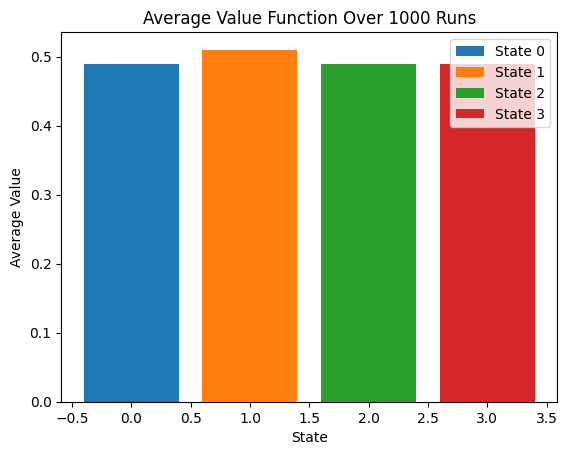

In [7]:
all_value_functions_PI_1 = []
all_policies_PI_1 = []

for _ in range(num_iterations):
    V, policy= policy_iteration(abstract_states, actions, abstract_transitions, abstract_reward)
    all_value_functions_PI_1.append(V)
    all_policies_PI_1.append(policy)

average_value_function_PI_1 = np.mean(all_value_functions_PI_1, axis=0)

# Plot average value - each state
for state in abstract_states[:-1]: #NON-TERMINAL states
    plt.bar(state, average_value_function_PI_1[state], label=f"State {state}")

plt.xlabel("State")
plt.ylabel("Average Value")
plt.title(f"Average Value Function Over {num_iterations} Runs")
plt.legend()
plt.show()

In [8]:
policy_counts_PI_1 = Counter(tuple(policy) for policy in all_policies_PI_1)

unique_policies_PI_1 = [np.array(policy) for policy in policy_counts_PI_1.keys()]
repeat_counts_PI_1 = list(policy_counts_PI_1.values())

unique_policies_PI_1, repeat_counts_PI_1

([array([0, 1, 0, 2, 0]), array([0, 0, 0, 0, 0]), array([1, 1, 1, 0, 0])],
 [544, 422, 34])

### Value Iteration

In [47]:
def value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon):
    #1. Initialize value function and policy for all states
    V = np.zeros(len(states))
    policy = np.zeros(len(states), dtype=int)

    iteration = 0
    history = []  # History for debugging

    while True:
        delta = 0
        iteration_values = V.copy()
        #2. Perform value iteration across all states

        for s in states:

            action_values = []
            best_action = None
            best_value = float('-inf')

            #2.1 Evaluate each action
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    reward_value = rewards(s, a, next_s)
                    value += prob * (reward_value + gamma * V[next_s])

                action_values.append(value)

            best_value = max(action_values)
            best_action = np.argmax(action_values)

            #2.2 Update the value function and policy
            delta = max(delta, abs(V[s] - best_value))
            V[s] = best_value
            policy[s] = best_action

        # Update the history (just for debugging)
        history.append(iteration_values)
        iteration += 1

        #3. Check for convergence
        if delta < epsilon:
            break

    return V, policy, history

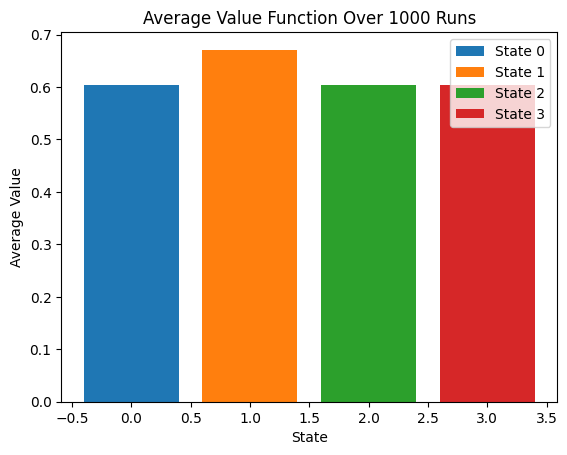

In [48]:
all_value_functions_VI_1 = []
all_policies_VI_1 = []

for _ in range(num_iterations):
    V, policy, history= value_iteration(abstract_states, actions, abstract_transitions, abstract_reward)
    all_value_functions_VI_1.append(V)
    all_policies_VI_1.append(policy)

average_value_function_VI_1 = np.mean(all_value_functions_VI_1, axis=0)

# Plot average value - each state
for state in abstract_states[:-1]: #NON-TERMINAL states
    plt.bar(state, average_value_function_VI_1[state], label=f"State {state}")

plt.xlabel("State")
plt.ylabel("Average Value")
plt.title(f"Average Value Function Over {num_iterations} Runs")
plt.legend()
plt.show()


In [11]:
policy_counts_VI_1 = Counter(tuple(policy) for policy in all_policies_VI_1)

unique_policies_VI_1 = [np.array(policy) for policy in policy_counts_VI_1.keys()]
repeat_counts_VI_1 = list(policy_counts_VI_1.values())

unique_policies_VI_1, repeat_counts_VI_1

([array([0, 1, 0, 2, 0]), array([0, 0, 0, 0, 0])], [655, 345])

#### Compare PI & VI:

In [56]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: policy_iteration(abstract_states, actions, abstract_transitions, abstract_reward), number=1)
    execution_time_VI = timeit.timeit(lambda: value_iteration(abstract_states, actions, abstract_transitions, abstract_reward), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00037 seconds
Avg Execution Time - VI: 0.00028 seconds


## 3.3.B

### Policy Iteration

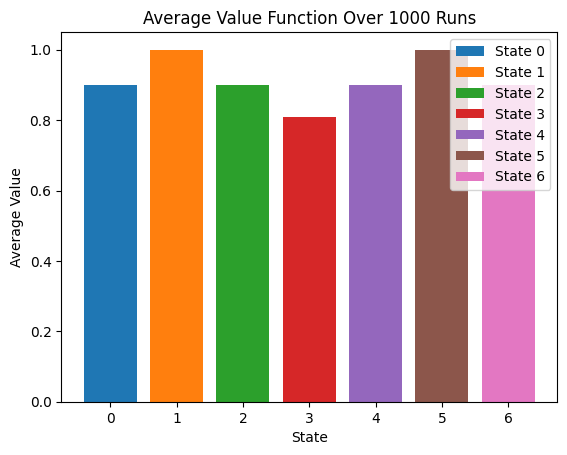

In [62]:
# Simply we can use previous policy_iteration function with real data:

all_value_functions_PI_2 = []
all_policies_PI_2 = []

for _ in range(num_iterations):
    V, policy= policy_iteration(states_in_real, actions_in_real, transitions_in_real, rewards_in_real)
    all_value_functions_PI_2.append(V)
    all_policies_PI_2.append(policy)

average_value_function_PI_2 = np.mean(all_value_functions_PI_2, axis=0)

# Plot average value - each state
for state in states_in_real[:-3]: #NON-TERMINAL states
    plt.bar(state, average_value_function_PI_2[state], label=f"State {state}")

plt.xlabel("State")
plt.ylabel("Average Value")
plt.title(f"Average Value Function Over {num_iterations} Runs")
plt.legend()
plt.show()

In [13]:
policy_counts_PI_2 = Counter(tuple(policy) for policy in all_policies_PI_2)

unique_policies_PI_2 = [np.array(policy) for policy in policy_counts_PI_2.keys()]
repeat_counts_PI_2 = list(policy_counts_PI_2.values())

unique_policies_PI_2, repeat_counts_PI_2

([array([0, 1, 2, 0, 0, 1, 2, 0, 0, 0])], [1000])

### Value Iteration

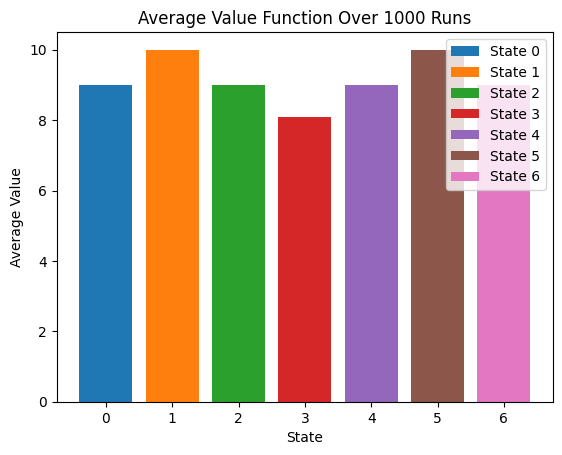

In [63]:
# Simply we can use previous value_iteration function with real data:

all_value_functions_VI_2 = []
all_policies_VI_2 = []

for _ in range(num_iterations):
    V, policy, history= value_iteration(states_in_real, actions_in_real, transitions_in_real, rewards_in_real)
    all_value_functions_VI_2.append(V)
    all_policies_VI_2.append(policy)

average_value_function_VI_2 = np.mean(all_value_functions_VI_2, axis=0)

# Plot average value - each state
for state in states_in_real[:-3]:
    plt.bar(state, average_value_function_VI_2[state], label=f"State {state}")

plt.xlabel("State")
plt.ylabel("Average Value")
plt.title(f"Average Value Function Over {num_iterations} Runs")
plt.legend()
plt.show()


In [15]:
policy_counts_VI_2 = Counter(tuple(policy) for policy in all_policies_VI_2)

unique_policies_VI_2 = [np.array(policy) for policy in policy_counts_VI_2.keys()]
repeat_counts_VI_2 = list(policy_counts_VI_2.values())

unique_policies_VI_2, repeat_counts_VI_2

([array([0, 1, 2, 2, 0, 1, 2, 0, 0, 0])], [1000])

#### Compare PI & VI:

In [58]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: policy_iteration(states_in_real, actions_in_real, transitions_in_real, rewards_in_real), number=1)
    execution_time_VI = timeit.timeit(lambda: value_iteration(states_in_real, actions_in_real, transitions_in_real, rewards_in_real), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00019 seconds
Avg Execution Time - VI: 0.00483 seconds


# <font color = lightGreen> Problem 4: </font>

## PART 1: (Questions)

### 4.1.D

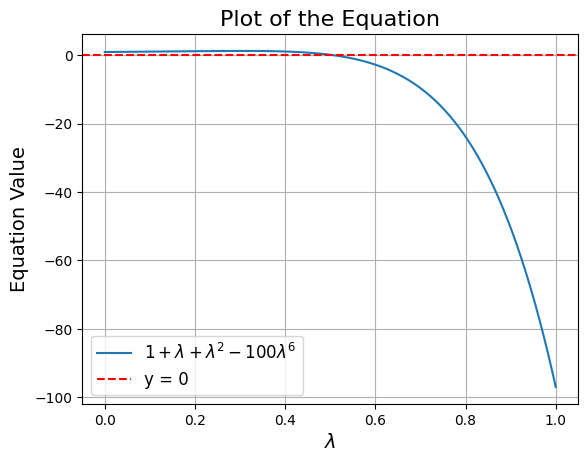

In [16]:
def equation_1(lambda_):
    return 1 + lambda_ + lambda_**2 - (100 * lambda_**6)

lambda_values = np.linspace(0, 1, 500)
equation_values = equation_1(lambda_values)

plt.plot(lambda_values, equation_values, label=r"$1 + \lambda + \lambda^2 - 100\lambda^6$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\lambda$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [17]:
lambda_sym = symbols('lambda', positive=True, real=True)
equation_1 = 1 + lambda_sym + lambda_sym**2 - 100 * lambda_sym**6

root1 = nsolve(equation_1, lambda_sym, 0.9)
root1

0.510558830219454

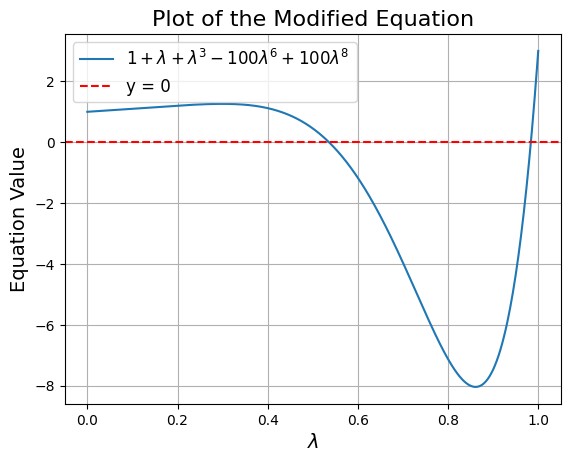

In [18]:
def equation_2(lambda_):
    return 1 + lambda_ + lambda_**3 - (100 * lambda_**6) + (100 * lambda_**8)

lambda_values = np.linspace(0, 1, 500)
modified_equation_values = equation_2(lambda_values)

plt.plot(lambda_values, modified_equation_values, label=r"$1 + \lambda + \lambda^3 - 100\lambda^6 + 100\lambda^8$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\lambda$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Modified Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [19]:
lambda_sym = symbols('lambda', positive=True, real=True)
equation_2 = 1 + lambda_sym + lambda_sym**3 - 100 * lambda_sym**6 + 100 * lambda_sym**8

roots = solveset(equation_2, lambda_sym, domain=Interval(0, 1))

root1 = nsolve(equation_2, lambda_sym, 0.5)
root2 = nsolve(equation_2, lambda_sym, 0.9)
(root1, root2)

(0.535996345399022, 0.983664801927083)

## PART 2: (Simulation)

### Define MDP parameters:

In [65]:
# --- State Space S: ---
states = list(range(11))

# --- Action Space A: ---
actions = ["Buy", "Sell"]

# --- Transition Probabilities P: ---
def transitions(current_s, a): #P(current_s,a) -> {next_s: probability = 1}
    next_s = 0
    probability = 1 # Deterministic

    if a == "Buy":
        if current_s < 10:
            next_s = current_s + 1
        else:
            next_s = current_s
    elif a == "Sell":
        if current_s > 0:
            next_s = current_s - 1
        else:
            next_s = current_s

    return {next_s: probability}


# --- Reward Function R: ---
def rewards(current_s, a, next_s):
    reward = 0
    if a == "Buy":
        if current_s == 9 and next_s == 10:
            reward = 100
        else:
            reward = 0
    elif a == "Sell":
        if current_s > 0 and next_s == current_s - 1:
            reward = 1
        else:
            reward = 0
    return reward


### 4.2.A.

#### Policy Iteration:

In [66]:
def finite_horizon_policy_iteration(states, actions, H, transitions, rewards, gamma = 1):
    #0. Initialize random policy
    policy = { (s, t): (np.random.choice(actions) if s != 10 else None) for s in states for t in range(H) }

    while True:
        #1. Initialize value function
        V = { (s, t): 0 for s in states for t in range(H+1) }

        #2. Policy Evaluation
        for t in range(H - 1, -1, -1):  # Iterate backward from H->0
            for s in states:
                if s == 10:  # Terminal state
                    continue
                a = policy[(s, t)]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])
                V[(s, t)] = value


        #3. Policy Improvement
        stable = True
        for t in range(H):
            for s in states:
                if s == 10:  # Terminal state
                    continue

                best_action = None
                best_value = float('-inf')

                for a in actions:
                    value = 0
                    for next_s, prob in transitions(s, a).items():
                        value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])
                    if value > best_value:
                        best_value = value
                        best_action = a

                if policy[(s, t)] != best_action:
                    stable = False
                    policy[(s, t)] = best_action

        if stable:
            break  # Policy has converged

    return policy , V

In [67]:
# For Debug:
H = 7
policy, V = finite_horizon_policy_iteration(states, actions, H, transitions, rewards)
V

{(0, 0): 3,
 (0, 1): 3,
 (0, 2): 2,
 (0, 3): 2,
 (0, 4): 1,
 (0, 5): 1,
 (0, 6): 0,
 (0, 7): 0,
 (1, 0): 4,
 (1, 1): 3,
 (1, 2): 3,
 (1, 3): 2,
 (1, 4): 2,
 (1, 5): 1,
 (1, 6): 1,
 (1, 7): 0,
 (2, 0): 4,
 (2, 1): 4,
 (2, 2): 3,
 (2, 3): 3,
 (2, 4): 2,
 (2, 5): 2,
 (2, 6): 1,
 (2, 7): 0,
 (3, 0): 100,
 (3, 1): 4,
 (3, 2): 4,
 (3, 3): 3,
 (3, 4): 3,
 (3, 5): 2,
 (3, 6): 1,
 (3, 7): 0,
 (4, 0): 100,
 (4, 1): 100,
 (4, 2): 4,
 (4, 3): 4,
 (4, 4): 3,
 (4, 5): 2,
 (4, 6): 1,
 (4, 7): 0,
 (5, 0): 101,
 (5, 1): 100,
 (5, 2): 100,
 (5, 3): 4,
 (5, 4): 3,
 (5, 5): 2,
 (5, 6): 1,
 (5, 7): 0,
 (6, 0): 101,
 (6, 1): 101,
 (6, 2): 100,
 (6, 3): 100,
 (6, 4): 3,
 (6, 5): 2,
 (6, 6): 1,
 (6, 7): 0,
 (7, 0): 102,
 (7, 1): 101,
 (7, 2): 101,
 (7, 3): 100,
 (7, 4): 100,
 (7, 5): 2,
 (7, 6): 1,
 (7, 7): 0,
 (8, 0): 102,
 (8, 1): 102,
 (8, 2): 101,
 (8, 3): 101,
 (8, 4): 100,
 (8, 5): 100,
 (8, 6): 1,
 (8, 7): 0,
 (9, 0): 103,
 (9, 1): 102,
 (9, 2): 102,
 (9, 3): 101,
 (9, 4): 101,
 (9, 5): 100,
 (9, 6): 1

#### Value Iteration:

In [68]:
def finite_horizon_value_iteration(states, actions, H, transitions, rewards, gamma = 1):
    # 1. Initialize value function for all states and time steps
    V = { (s, t): 0 for s in states for t in range(H+1) }
    policy = { (s, t): None for s in states for t in range(H) }

    # 2. Perform value iteration backward from horizon H
    for t in range(H - 1, -1, -1):  # Iterate backward from H-1 to 0
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            #2.1. Evaluate each action
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])

                if value > best_value:
                    best_value = value
                    best_action = a

            #2.2. Update the value function and policy
            V[(s, t)] = best_value
            policy[(s, t)] = best_action

    return policy, V


In [69]:
# For Debug:
H = 7
policy, V = finite_horizon_value_iteration(states, actions, H, transitions, rewards)
V


{(0, 0): 3,
 (0, 1): 3,
 (0, 2): 2,
 (0, 3): 2,
 (0, 4): 1,
 (0, 5): 1,
 (0, 6): 0,
 (0, 7): 0,
 (1, 0): 4,
 (1, 1): 3,
 (1, 2): 3,
 (1, 3): 2,
 (1, 4): 2,
 (1, 5): 1,
 (1, 6): 1,
 (1, 7): 0,
 (2, 0): 4,
 (2, 1): 4,
 (2, 2): 3,
 (2, 3): 3,
 (2, 4): 2,
 (2, 5): 2,
 (2, 6): 1,
 (2, 7): 0,
 (3, 0): 100,
 (3, 1): 4,
 (3, 2): 4,
 (3, 3): 3,
 (3, 4): 3,
 (3, 5): 2,
 (3, 6): 1,
 (3, 7): 0,
 (4, 0): 100,
 (4, 1): 100,
 (4, 2): 4,
 (4, 3): 4,
 (4, 4): 3,
 (4, 5): 2,
 (4, 6): 1,
 (4, 7): 0,
 (5, 0): 101,
 (5, 1): 100,
 (5, 2): 100,
 (5, 3): 4,
 (5, 4): 3,
 (5, 5): 2,
 (5, 6): 1,
 (5, 7): 0,
 (6, 0): 101,
 (6, 1): 101,
 (6, 2): 100,
 (6, 3): 100,
 (6, 4): 3,
 (6, 5): 2,
 (6, 6): 1,
 (6, 7): 0,
 (7, 0): 102,
 (7, 1): 101,
 (7, 2): 101,
 (7, 3): 100,
 (7, 4): 100,
 (7, 5): 2,
 (7, 6): 1,
 (7, 7): 0,
 (8, 0): 102,
 (8, 1): 102,
 (8, 2): 101,
 (8, 3): 101,
 (8, 4): 100,
 (8, 5): 100,
 (8, 6): 1,
 (8, 7): 0,
 (9, 0): 103,
 (9, 1): 102,
 (9, 2): 102,
 (9, 3): 101,
 (9, 4): 101,
 (9, 5): 100,
 (9, 6): 1

#### Simulation

In [70]:
def simulate_actions_for_horizon(H, start_state, states, actions, transitions, rewards, algorithm, gamma = 1):
    # Compute the optimal policy for the horizon
    policy, _ = algorithm(states, actions, H, transitions, rewards, gamma)

    # Simulate the trajectory
    current_state = start_state
    trajectory = []
    for t in range(H):
        if current_state == 10:  # Terminal state
            trajectory.append((t, current_state, None))
            break

        # Get the action from policy
        action = policy.get((current_state, t), None)
        trajectory.append((t, current_state, action))

        # Updating state
        next_states = transitions(current_state, action)
        current_state = list(next_states.keys())[0]  # Deterministic transition, all probabilities = 1.0

    return trajectory


def simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, algorithm, gamma = 1):
    for H in Hs:
        # Simulate the trajectory for the given H
        trajectory = simulate_actions_for_horizon(H, start_state, states, actions, transitions, rewards, algorithm, gamma)

        buy_count = sum(1 for _, _, a in trajectory if a == "Buy")
        sell_count = sum(1 for _, _, a in trajectory if a == "Sell")

        # Categorize the policy
        if sell_count == 0:
            policy_type = "Buy-only policy"
        elif buy_count == 0:
            policy_type = "Sell-only policy"
        else:
            policy_type = "Mixed policy (buy and sell)"

        # Results
        print(f"H = {H},\t#Sell = {sell_count},\t#Buy = {buy_count},\t-> {policy_type}")
        for t, s, a in trajectory:
            print(f"Time Step: {t}, State: {s}, Action: {a}")
        print(10 * "___")


In [71]:
Hs = [3, 5, 7, 8, 9, 12]
start_state = 3


In [72]:
print("PI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)


PI:
H = 3,	#Sell = 3,	#Buy = 0,	-> Sell-only policy
Time Step: 0, State: 3, Action: Sell
Time Step: 1, State: 2, Action: Sell
Time Step: 2, State: 1, Action: Sell
______________________________
H = 5,	#Sell = 4,	#Buy = 1,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Sell
Time Step: 2, State: 3, Action: Sell
Time Step: 3, State: 2, Action: Sell
Time Step: 4, State: 1, Action: Sell
______________________________
H = 7,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Buy
______________________________
H = 8,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 

In [73]:
print("VI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)



VI:
H = 3,	#Sell = 3,	#Buy = 0,	-> Sell-only policy
Time Step: 0, State: 3, Action: Sell
Time Step: 1, State: 2, Action: Sell
Time Step: 2, State: 1, Action: Sell
______________________________
H = 5,	#Sell = 4,	#Buy = 1,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Sell
Time Step: 2, State: 3, Action: Sell
Time Step: 3, State: 2, Action: Sell
Time Step: 4, State: 1, Action: Sell
______________________________
H = 7,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Buy
______________________________
H = 8,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 

#### Compare PI & VI:

In [74]:
Hs = [np.random.randint(20)]
start = np.random.randint(10)
print("PI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)
print("VI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)


PI:
H = 15,	#Sell = 4,	#Buy = 11,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Sell
Time Step: 7, State: 8, Action: Buy
Time Step: 8, State: 9, Action: Sell
Time Step: 9, State: 8, Action: Buy
Time Step: 10, State: 9, Action: Sell
Time Step: 11, State: 8, Action: Buy
Time Step: 12, State: 9, Action: Sell
Time Step: 13, State: 8, Action: Buy
Time Step: 14, State: 9, Action: Buy
______________________________
VI:
H = 15,	#Sell = 4,	#Buy = 11,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Sell
Time Step: 7, State: 8, Action: Buy
T

In [77]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: finite_horizon_policy_iteration(states, actions, H, transitions, rewards), number=1)
    execution_time_VI = timeit.timeit(lambda: finite_horizon_value_iteration(states, actions, H, transitions, rewards), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.08213 seconds
Avg Execution Time - VI: 0.00696 seconds


### 4.2.B. 

In [31]:
gamma_0 = 0
epsilon = 1e-5

#### Policy Iteration

In [32]:
def infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon):
    # 0. Initialize random policy
    policy = {s: (np.random.choice(actions) if s != 10 else None) for s in states}

    while True:
        #1. Initialize value function
        V = {s: 0 for s in states}

        #2. Policy Evaluation
        while True:
            delta = 0
            for s in states:
                if s == 10:  # Terminal state
                    continue
                a = policy[s]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])
                delta = max(delta, abs(V[s] - value))
                V[s] = value
            if delta < epsilon:  # Value function has converged
                break

        #3. Policy Improvement
        stable = True
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])
                if value > best_value:
                    best_value = value
                    best_action = a

            if policy[s] != best_action:
                stable = False
                policy[s] = best_action

        if stable:
            break  # Policy has converged

    return policy, V


In [33]:
policy, V= infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon)
policy

{0: 'Buy',
 1: 'Sell',
 2: 'Sell',
 3: 'Sell',
 4: 'Sell',
 5: 'Sell',
 6: 'Sell',
 7: 'Sell',
 8: 'Sell',
 9: 'Buy',
 10: None}

#### Value Iteration

In [78]:
def infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon):
    #1. Initialize value function and policy for all states
    V = {s: 0 for s in states}
    policy = {s: None for s in states}

    while True:
        delta = 0
        #2. Perform value iteration across all states
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            #2.1 Evaluate each action
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])

                if value > best_value:
                    best_value = value
                    best_action = a

            #2.2 Update the value function and policy
            delta = max(delta, abs(V[s] - best_value))
            V[s] = best_value
            policy[s] = best_action

        #3. Check for convergence
        if delta < epsilon:  # Value function has converged
            break

    return policy, V


In [79]:
policy, V= infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon)
policy

{0: 'Buy',
 1: 'Sell',
 2: 'Sell',
 3: 'Sell',
 4: 'Sell',
 5: 'Sell',
 6: 'Sell',
 7: 'Sell',
 8: 'Sell',
 9: 'Buy',
 10: None}

#### Compare PI & VI:

In [36]:
print("PI:")
policy_PI, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon)
print(policy_PI)
print("VI:")
policy_VI, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon)
print(policy_VI)


PI:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}
VI:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}


In [37]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: infinite_horizon_policy_iteration(states, actions, transitions, rewards,gamma=gamma_0, epsilon=epsilon), number=1)
    execution_time_VI = timeit.timeit(lambda: infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma_0, epsilon=epsilon), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00014 seconds
Avg Execution Time - VI: 0.00002 seconds


### 4.2.C. 

In [38]:
gammas = [0.0, 0.1, 0.5, 0.9]

#### Policy Iteration

In [81]:
gammas = [0.0, 0.1, 0.5, 0.55, 0.99, 0.999]
for gamma in gammas:
    print(f"gamma = {gamma}:")
    policy, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon)
    print(policy)
    print("")


gamma = 0.0:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}

gamma = 0.1:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.55:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.99:
{0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.999:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Sell', 10: None}



#### Value Iteration

In [82]:
gammas = [0.0, 0.1, 0.5, 0.55, 0.9, 0.999]
for gamma in gammas:
    print(f"gamma = {gamma}:")
    policy, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon)
    print(policy)
    print("")

gamma = 0.0:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}

gamma = 0.1:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.55:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.9:
{0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.999:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Sell', 10: None}



#### Compare PI & VI:

In [84]:
for i in range(5):
    gamma = np.random.uniform()
    print(f"gamma = {gamma}:")
    policy_VI, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon)
    policy_PI, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon)
    if policy_PI == policy_VI:
        print("SAME")
        print("Policy:", policy_PI)
    else:
        print(f"policy_PI = {policy_PI}" )
        print(f"policy_VI = {policy_VI}" )

    print("")

gamma = 0.360686129038607:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.7327282774798201:
SAME
Policy: {0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5873137696902417:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.527965858576793:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.651322721722004:
SAME
Policy: {0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}



In [85]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    gamma = np.random.uniform()
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon), number=1)
    execution_time_VI = timeit.timeit(lambda: infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=epsilon), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00122 seconds
Avg Execution Time - VI: 0.00010 seconds
